# 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


# 2. Load Dataset

In [2]:
from pathlib import Path

DATA_PATH = (
    Path("../data/winequality-red.csv")
    if Path("../data/winequality-red.csv").exists()
    else Path("data/winequality-red.csv")
)

df = pd.read_csv(DATA_PATH, sep=";")

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


# 3. Dataset Understanding

In [3]:
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Dataset shape: (1599, 12)

Columns:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Data types:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object


In [4]:
print("Missing values:")
print(df.isnull().sum())
print("Missing values:")
print(df.isnull().sum())

Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64
Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [5]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 240


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


In [7]:
print(df["quality"].value_counts().sort_index())

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


# 4. Exploratory Data Analysis
    ├── Quality Distribution
    ├── Feature Distributions
    ├── Boxplots
    ├── Correlation Heatmap
    └── Feature-Quality Analysis

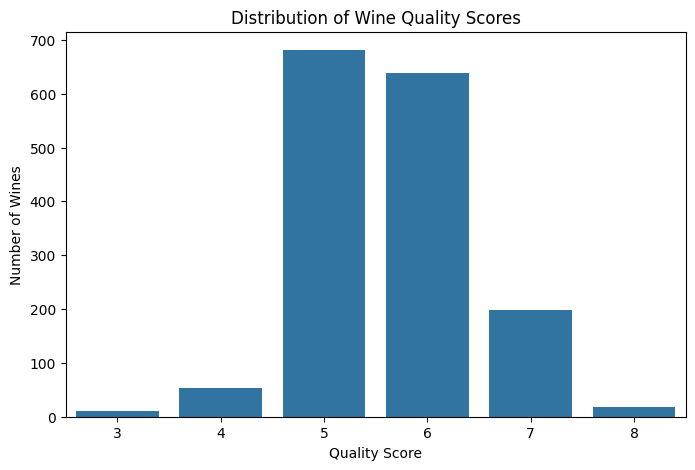

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="quality")

plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Quality Score")
plt.ylabel("Number of Wines")

plt.show()

In [9]:
print(df.shape)
print(df.columns.tolist())
print(df.isnull().sum())
print(df.duplicated().sum())
print(df["quality"].value_counts().sort_index())

(1599, 12)
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64
240
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


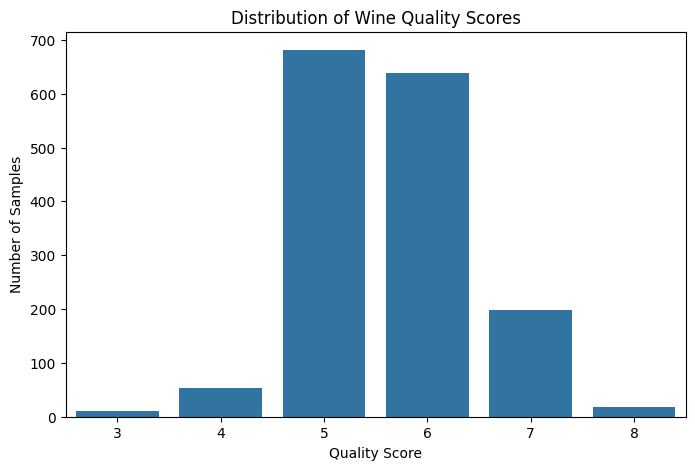

In [10]:
quality_counts = df["quality"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=quality_counts.index,
    y=quality_counts.values
)

plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Quality Score")
plt.ylabel("Number of Samples")

plt.show()

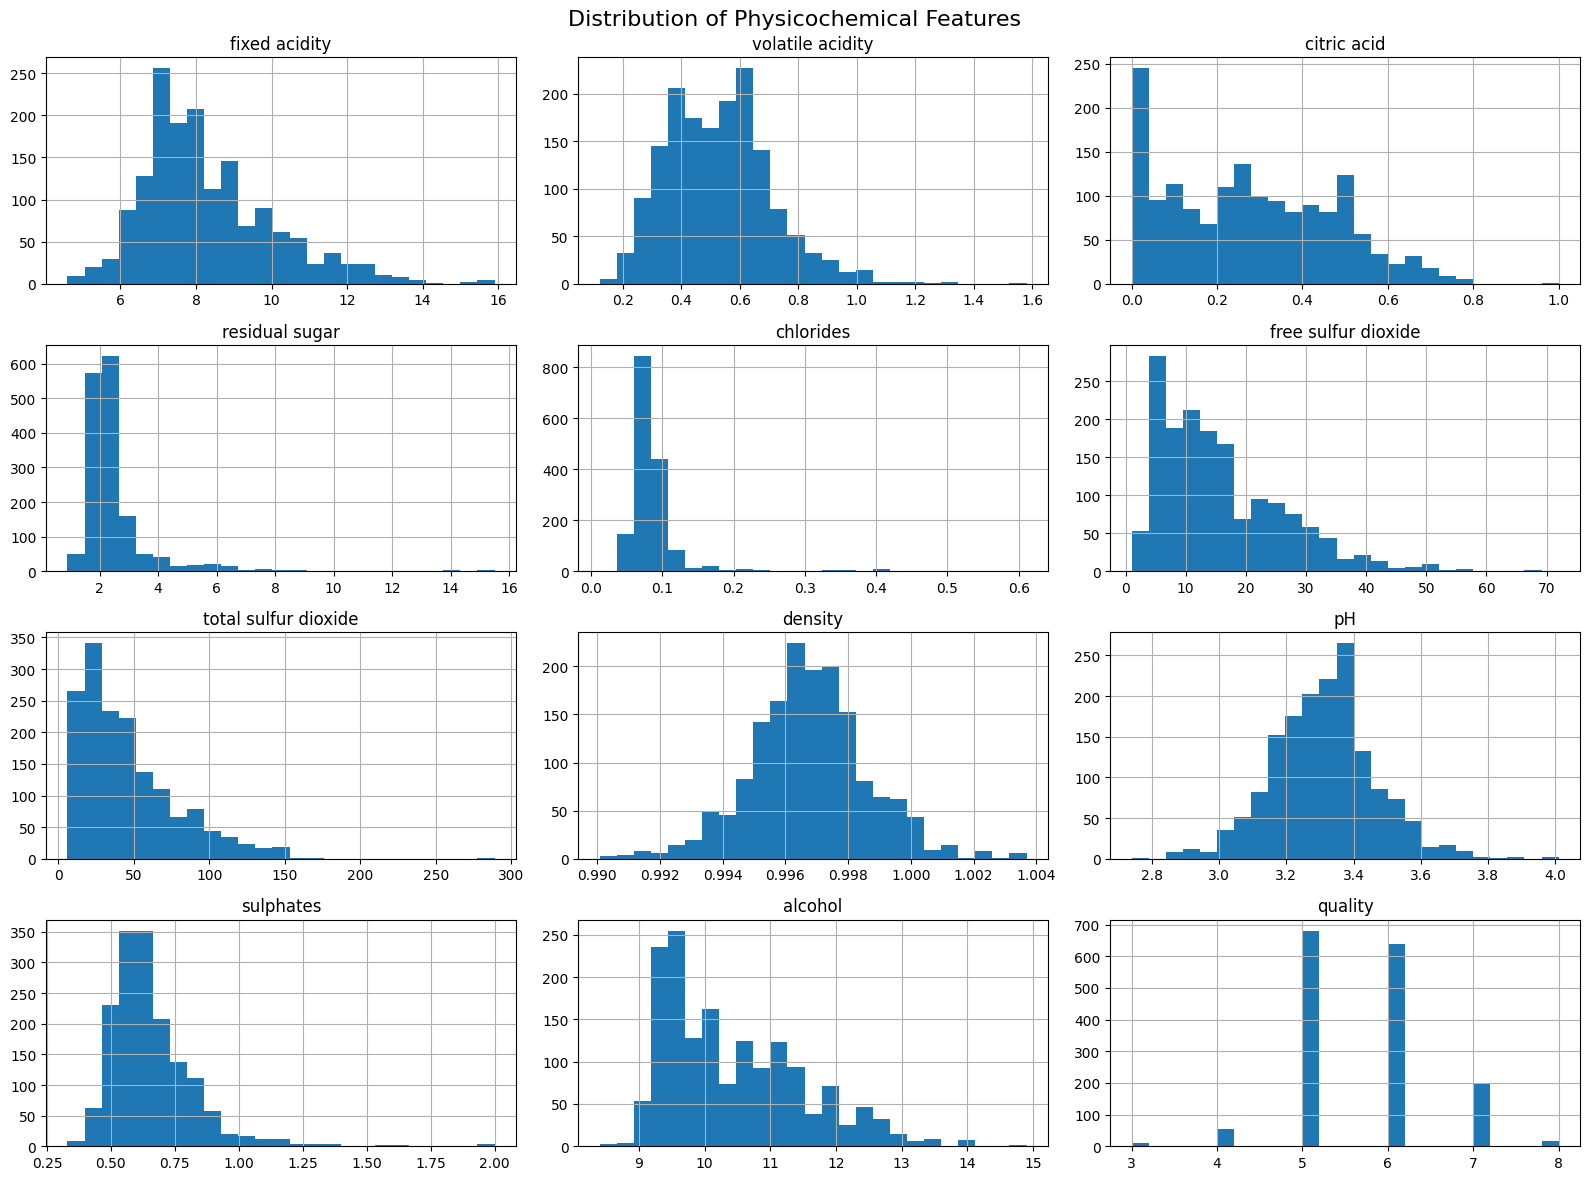

In [11]:
df.hist(
    figsize=(16, 12),
    bins=25
)

plt.suptitle(
    "Distribution of Physicochemical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

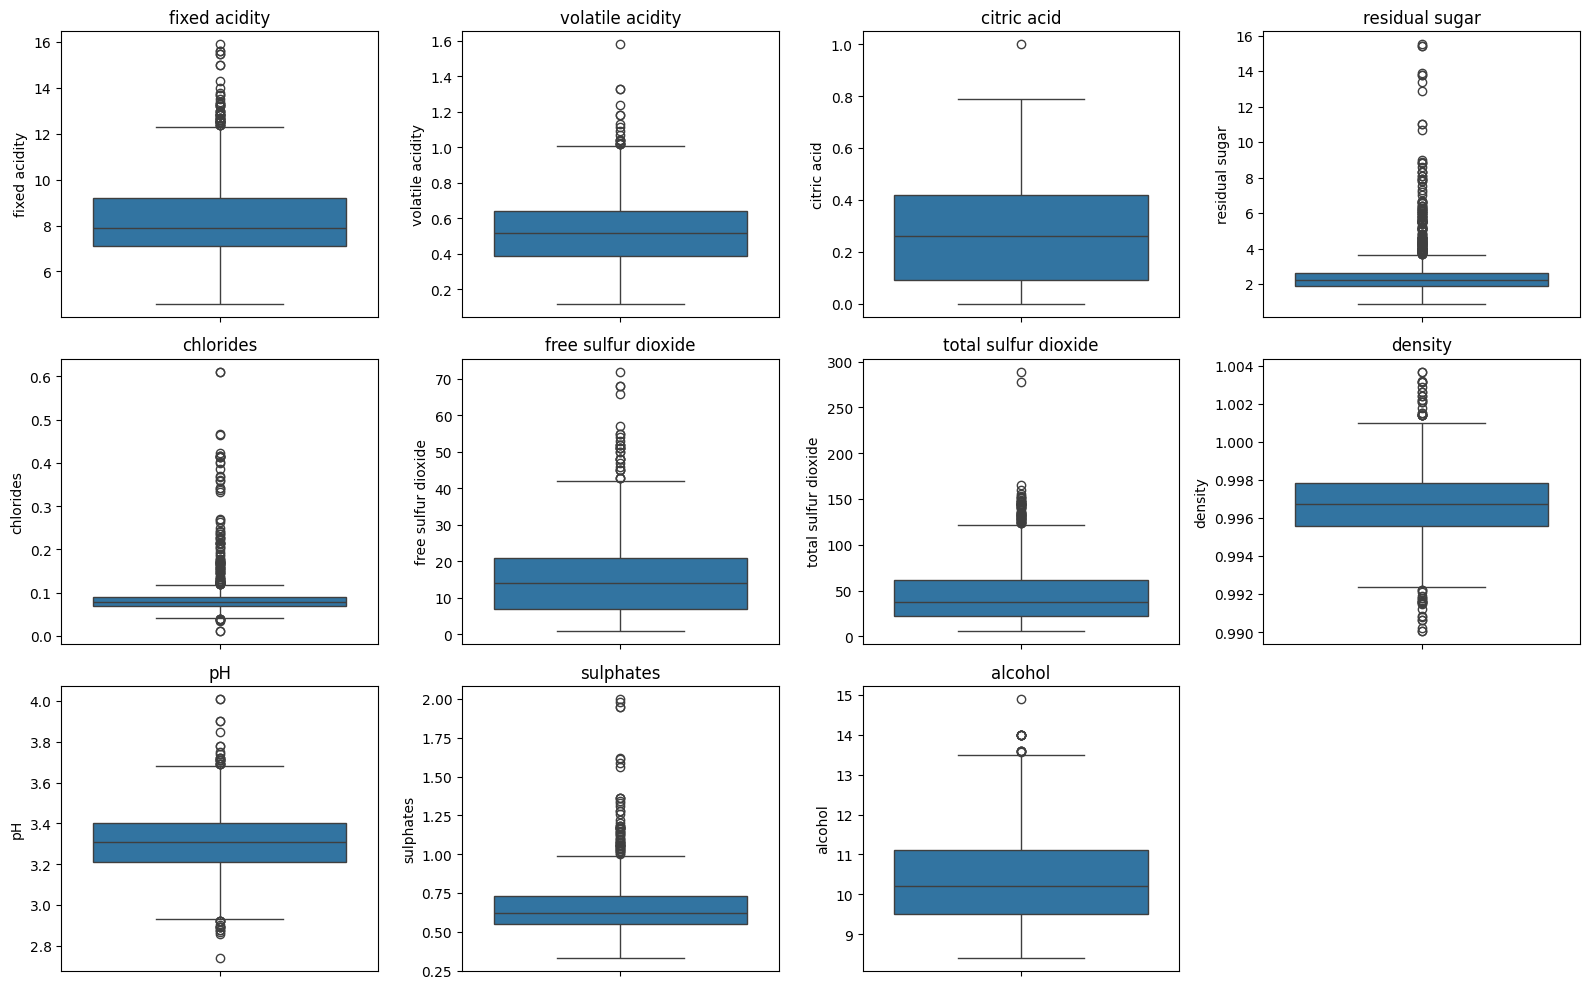

In [12]:
features = df.drop(columns=["quality"])

plt.figure(figsize=(16, 10))

for i, column in enumerate(features.columns, 1):
    plt.subplot(3, 4, i)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

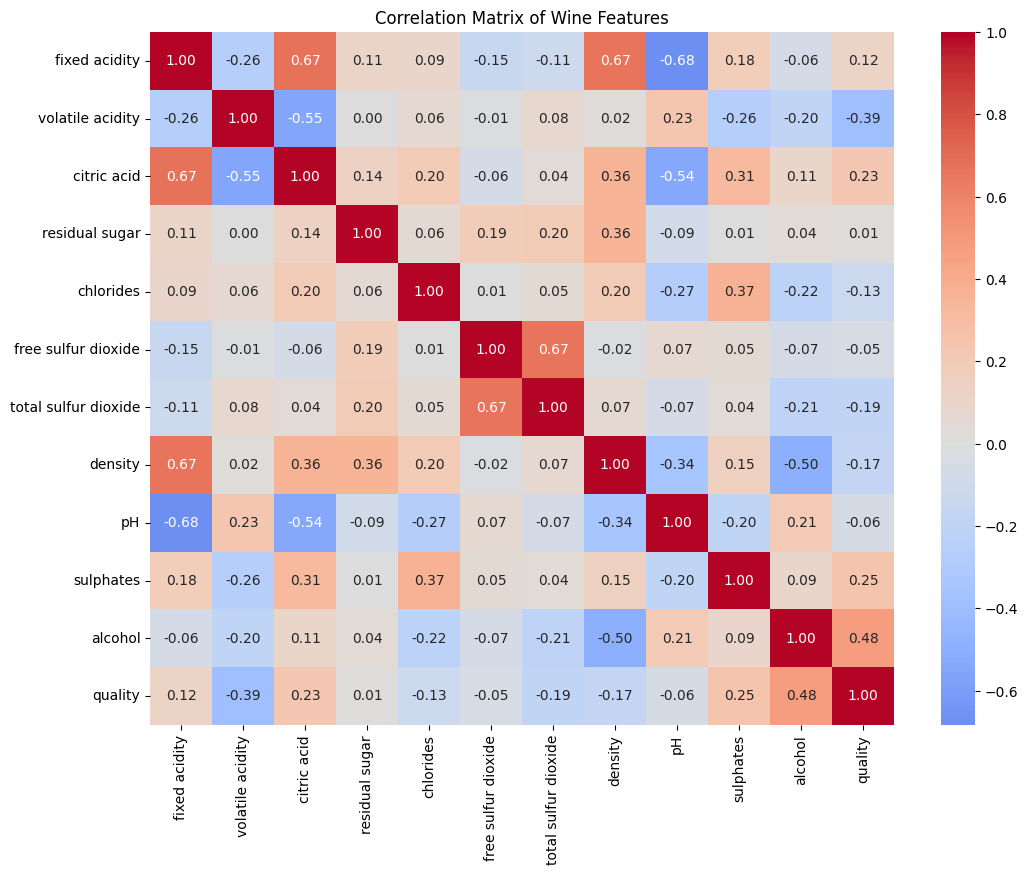

In [13]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Wine Features")

plt.show()


In [14]:
quality_correlations = (
    correlation_matrix["quality"]
    .drop("quality")
    .sort_values(ascending=False)
)

print(quality_correlations)

alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64


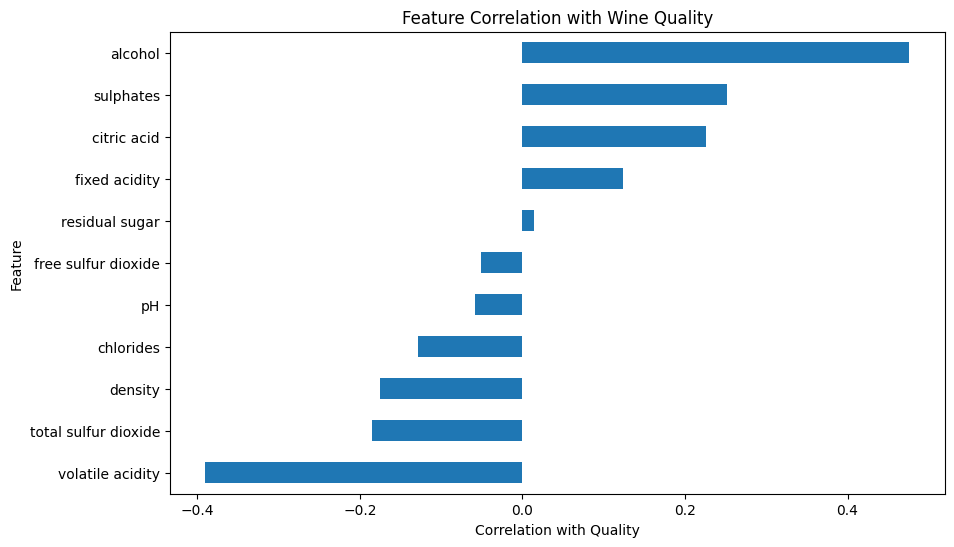

In [15]:
plt.figure(figsize=(10, 6))

quality_correlations.sort_values().plot(kind="barh")

plt.title("Feature Correlation with Wine Quality")
plt.xlabel("Correlation with Quality")
plt.ylabel("Feature")

plt.show()

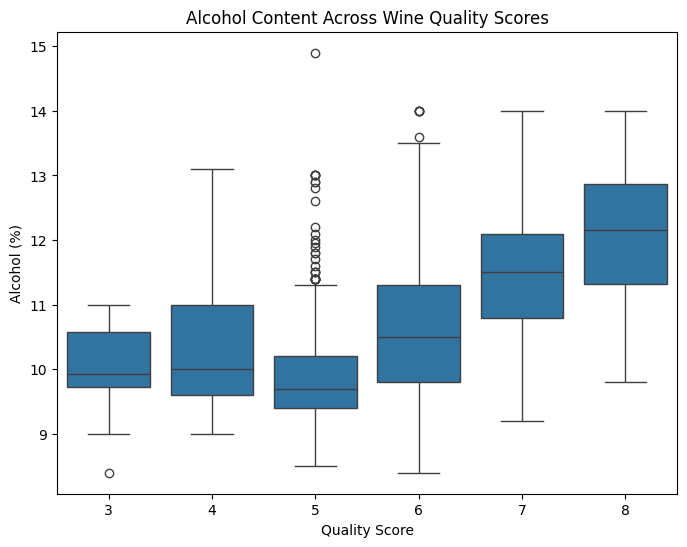

In [16]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="quality",
    y="alcohol"
)

plt.title("Alcohol Content Across Wine Quality Scores")
plt.xlabel("Quality Score")
plt.ylabel("Alcohol (%)")

plt.show()

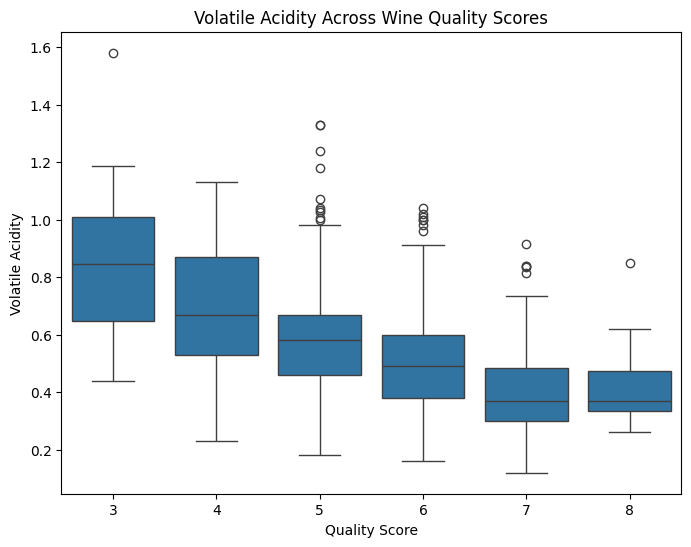

In [17]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="quality",
    y="volatile acidity"
)

plt.title("Volatile Acidity Across Wine Quality Scores")
plt.xlabel("Quality Score")
plt.ylabel("Volatile Acidity")

plt.show()

### Key EDA Insights & Analytical Takeaways
Based on the exploratory data visualizations above:
- **Quality Distribution & Class Imbalance:** Wine quality scores are concentrated around scores 5 and 6 (representing ~86.5% of samples), with high-quality wines (scores 7 and 8) representing a minority (~13.5%). Scores 3 and 4 are relatively rare.
- **Strongest Positive Association:** Alcohol has the strongest positive linear correlation with quality ( = +0.48$), where higher-quality wines generally have higher median alcohol content.
- **Negative Sensory Relationship:** Volatile acidity has a negative relationship with quality ( = -0.40$), indicating that higher acetic acid content detracts from wine quality.
- **Statistical Outliers:** Boxplot analysis shows several physicochemical features contain statistical outliers beyond .5 	imes 	ext{IQR}$, notably residual sugar, chlorides, and sulfur dioxide.
- **Feature Intercorrelations:** The correlation heatmap demonstrates that several physicochemical features are correlated with each other (e.g., fixed acidity correlates positively with density and citric acid, and negatively with pH).

# 5. Data Preprocessing

In [18]:
df_clean = df.copy()

print("Original dataset shape:", df_clean.shape)

duplicate_count = df_clean.duplicated().sum()

print("Duplicate rows:", duplicate_count)

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df_clean.shape)

Original dataset shape: (1599, 12)
Duplicate rows: 240
Shape after removing duplicates: (1359, 12)


In [19]:
print(df_clean["quality"].value_counts().sort_index())

quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


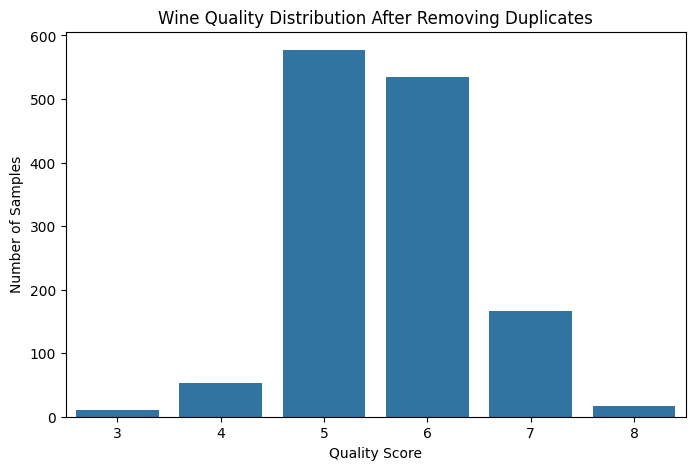

In [20]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="quality"
)

plt.title("Wine Quality Distribution After Removing Duplicates")
plt.xlabel("Quality Score")
plt.ylabel("Number of Samples")

plt.show()

#Detect outliers using IQR
IQR is a robust statistical method for identifying potential outliers. It is less affected by extreme values than methods based purely on mean and standard deviation. Since several wine chemical measurements are skewed, IQR provides a suitable initial method for detecting extreme observations.

In [21]:
numeric_features = df_clean.drop(columns=["quality"]).columns

outlier_summary = []

for column in numeric_features:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df_clean[
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ]
    
    outlier_summary.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier %": round(
            len(outliers) / len(df_clean) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_summary)

outlier_df

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,fixed acidity,7.1000,9.20000,2.10000,3.95000,12.35000,41,3.02
1,volatile acidity,0.3900,0.64000,0.25000,0.01500,1.01500,19,1.40
2,citric acid,0.0900,0.43000,0.34000,-0.42000,0.94000,1,0.07
3,residual sugar,1.9000,2.60000,0.70000,0.85000,3.65000,126,9.27
4,chlorides,0.0700,0.09100,0.02100,0.03850,0.12250,87,6.40
5,free sulfur dioxide,7.0000,21.00000,14.00000,-14.00000,42.00000,26,1.91
6,total sulfur dioxide,22.0000,63.00000,41.00000,-39.50000,124.50000,45,3.31
7,density,0.9956,0.99782,0.00222,0.99227,1.00115,35,2.58
8,pH,3.2100,3.40000,0.19000,2.92500,3.68500,28,2.06
9,sulphates,0.5500,0.73000,0.18000,0.28000,1.00000,55,4.05


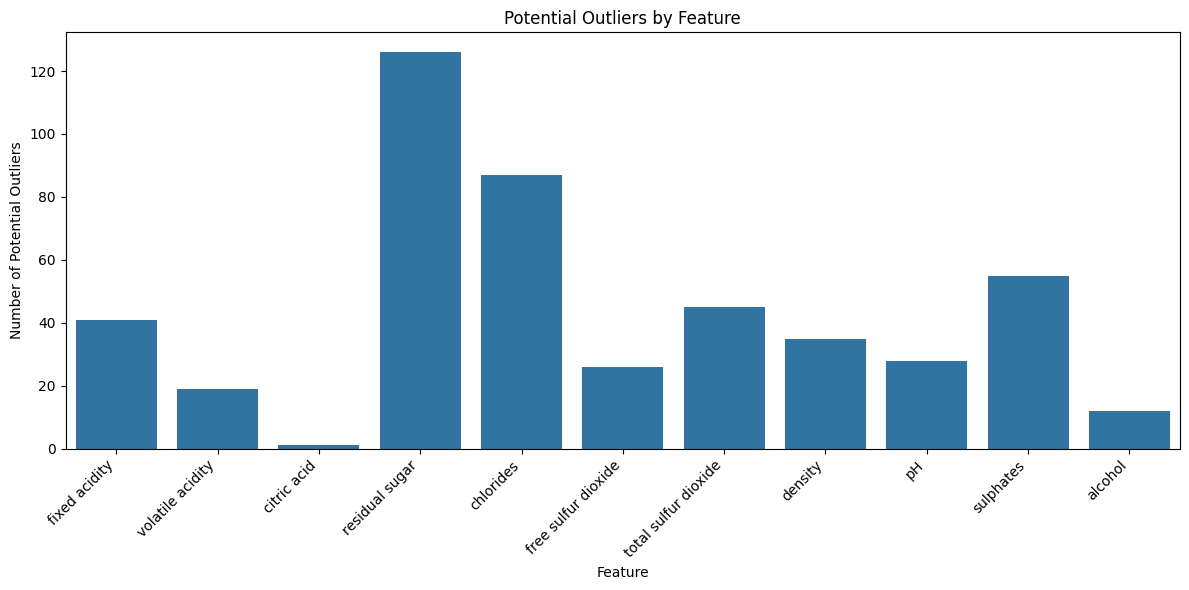

In [22]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=outlier_df,
    x="Feature",
    y="Outlier Count"
)

plt.xticks(rotation=45, ha="right")

plt.title("Potential Outliers by Feature")
plt.xlabel("Feature")
plt.ylabel("Number of Potential Outliers")

plt.tight_layout()
plt.show()

In [23]:
print(df_clean.shape)
print(df_clean["quality"].value_counts().sort_index())
outlier_df


(1359, 12)
quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,fixed acidity,7.1000,9.20000,2.10000,3.95000,12.35000,41,3.02
1,volatile acidity,0.3900,0.64000,0.25000,0.01500,1.01500,19,1.40
2,citric acid,0.0900,0.43000,0.34000,-0.42000,0.94000,1,0.07
3,residual sugar,1.9000,2.60000,0.70000,0.85000,3.65000,126,9.27
4,chlorides,0.0700,0.09100,0.02100,0.03850,0.12250,87,6.40
5,free sulfur dioxide,7.0000,21.00000,14.00000,-14.00000,42.00000,26,1.91
6,total sulfur dioxide,22.0000,63.00000,41.00000,-39.50000,124.50000,45,3.31
7,density,0.9956,0.99782,0.00222,0.99227,1.00115,35,2.58
8,pH,3.2100,3.40000,0.19000,2.92500,3.68500,28,2.06
9,sulphates,0.5500,0.73000,0.18000,0.28000,1.00000,55,4.05


Create the classification target

In [24]:
def classify_quality(quality):
    if quality <= 5:
        return "Low"
    elif quality == 6:
        return "Medium"
    else:
        return "High"


df_clean["quality_category"] = df_clean["quality"].apply(classify_quality)

print(df_clean[["quality", "quality_category"]].head(10))

   quality quality_category
0        5              Low
1        5              Low
2        5              Low
3        6           Medium
4        5              Low
5        5              Low
6        7             High
7        7             High
8        5              Low
9        5              Low


Check the new class distribution

In [25]:
class_counts = df_clean["quality_category"].value_counts()

print(class_counts)

print("\nPercentage distribution:")
print(
    df_clean["quality_category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

quality_category
Low       640
Medium    535
High      184
Name: count, dtype: int64

Percentage distribution:
quality_category
Low       47.09
Medium    39.37
High      13.54
Name: proportion, dtype: float64


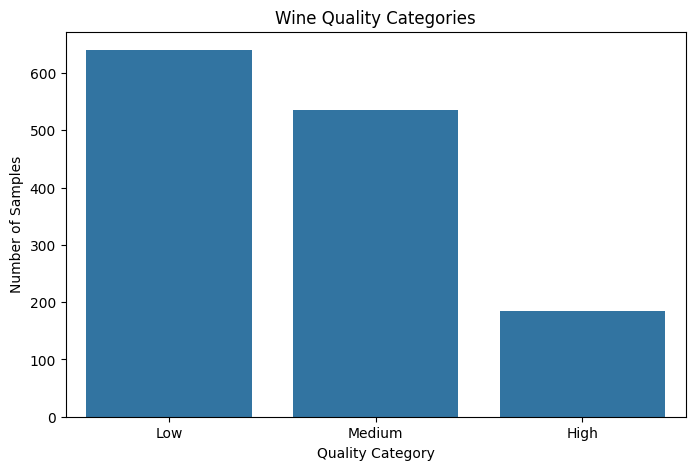

In [26]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="quality_category",
    order=["Low", "Medium", "High"]
)

plt.title("Wine Quality Categories")
plt.xlabel("Quality Category")
plt.ylabel("Number of Samples")

plt.show()

Separate features and target
X = input features
y = target

In [27]:
X = df_clean.drop(
    columns=["quality", "quality_category"]
)

y = df_clean["quality_category"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1359, 11)
y shape: (1359,)


Train/test split
Now we'll split the data.

Using a stratified split
Why stratify=y?-> Because the target classes are imbalanced. Stratification maintains approximately the same class distribution in both training and testing sets, giving a more representative evaluation

In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1087
Testing samples: 272


In [29]:
X_train_processed = X_train.copy()
X_test_processed = X_test.copy()

outlier_bounds = {}

for column in X_train.columns:

    Q1 = X_train[column].quantile(0.25)
    Q3 = X_train[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_bounds[column] = (
        lower_bound,
        upper_bound
    )

    # Cap extreme values instead of deleting rows
    X_train_processed[column] = X_train_processed[column].clip(
        lower=lower_bound,
        upper=upper_bound
    )

    X_test_processed[column] = X_test_processed[column].clip(
        lower=lower_bound,
        upper=upper_bound
    )

print("Outlier treatment completed.")

Outlier treatment completed.


## Feature Scaling

StandardScaler is applied to the training features for algorithms that are sensitive to feature magnitude, particularly Logistic Regression and KNN.

The scaler is fitted only on the training data to prevent data leakage.

In [30]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train_processed)

# Apply the same transformation to test data
X_test_scaled = scaler.transform(X_test_processed)

print("Scaling completed successfully.")
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

Scaling completed successfully.
X_train_scaled shape: (1087, 11)
X_test_scaled shape: (272, 11)


In [31]:
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nMaximum values before treatment:")
print(X_train.max())

print("\nMaximum values after treatment:")
print(X_train_processed.max())

Original training shape: (1087, 11)
Processed training shape: (1087, 11)

Maximum values before treatment:
fixed acidity            15.9000
volatile acidity          1.5800
citric acid               1.0000
residual sugar           13.9000
chlorides                 0.6110
free sulfur dioxide      68.0000
total sulfur dioxide    289.0000
density                   1.0032
pH                        4.0100
sulphates                 2.0000
alcohol                  14.9000
dtype: float64

Maximum values after treatment:
fixed acidity            12.350000
volatile acidity          1.011250
citric acid               0.940000
residual sugar            3.650000
chlorides                 0.122500
free sulfur dioxide      42.000000
total sulfur dioxide    124.500000
density                   1.001288
pH                        3.685000
sulphates                 1.000000
alcohol                  13.750000
dtype: float64


# Model Training
1. Logistic Regression
2. KNN
3. Decision Tree
4. Random Forest
5. Gradient Boosting

In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Define the five required models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=7
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

# Train Logistic Regression and KNN on scaled data
models["Logistic Regression"].fit(X_train_scaled, y_train)
models["KNN"].fit(X_train_scaled, y_train)

# Train tree-based models on processed but unscaled data
models["Decision Tree"].fit(X_train_processed, y_train)
models["Random Forest"].fit(X_train_processed, y_train)
models["Gradient Boosting"].fit(X_train_processed, y_train)

print("All 5 models trained successfully!")

All 5 models trained successfully!


## Model Evaluation

In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

results = []
predictions = {}

for name, model in models.items():

    if name in ["Logistic Regression", "KNN"]:
        y_pred = model.predict(X_test_scaled)
    else:
        y_pred = model.predict(X_test_processed)

    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.5919,0.5691,0.6275,0.5872
1,KNN,0.5882,0.5620,0.5575,0.5591
2,Decision Tree,0.5294,0.5097,0.5366,0.5142
3,Random Forest,0.6029,0.5891,0.5912,0.5899
4,Gradient Boosting,0.6176,0.6344,0.5706,0.5919


## Per-Class Performance

In [34]:
for name, y_pred in predictions.items():

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=["Low", "Medium", "High"],
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

         Low       0.67      0.69      0.68       128
      Medium       0.52      0.41      0.46       107
        High       0.52      0.78      0.62        37

    accuracy                           0.59       272
   macro avg       0.57      0.63      0.59       272
weighted avg       0.59      0.59      0.58       272


KNN
              precision    recall  f1-score   support

         Low       0.67      0.72      0.69       128
      Medium       0.51      0.47      0.49       107
        High       0.51      0.49      0.50        37

    accuracy                           0.59       272
   macro avg       0.56      0.56      0.56       272
weighted avg       0.58      0.59      0.58       272


Decision Tree
              precision    recall  f1-score   support

         Low       0.69      0.55      0.61       128
      Medium       0.46      0.50      0.48       107
        High       0.38      0.57 

## Confusion Matrices

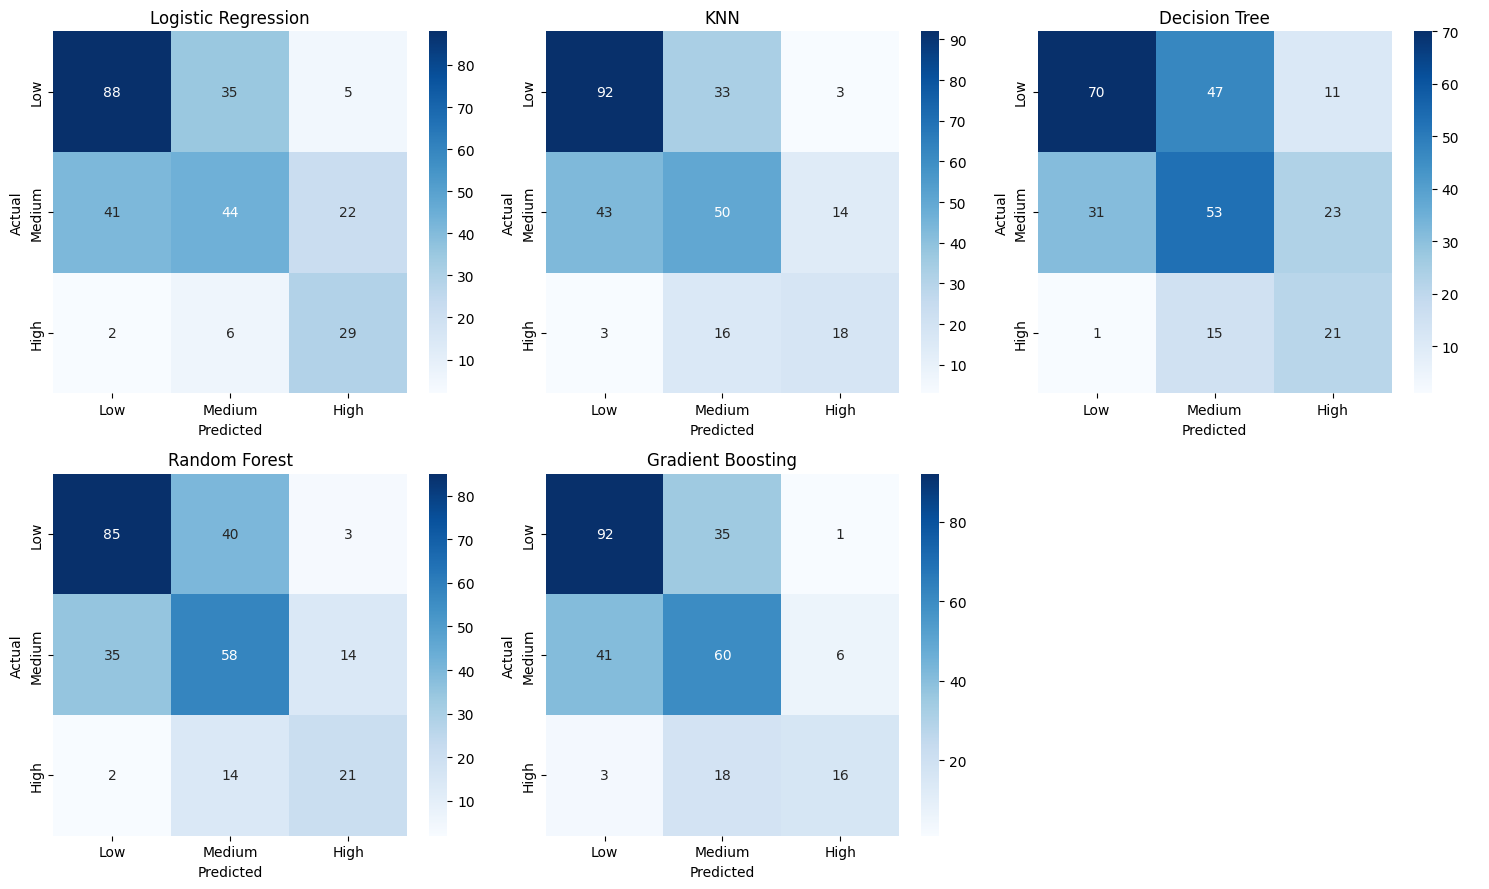

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(predictions.items()):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["Low", "Medium", "High"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Low", "Medium", "High"],
        yticklabels=["Low", "Medium", "High"],
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

axes[-1].axis("off")

plt.tight_layout()
plt.show()

## 5-Fold Cross-Validation
The training data is divided into five parts. Each part becomes the validation set once while the remaining four parts are used for training.

This provides a more reliable estimate than relying on only one train/test split.

In [36]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.base import clone

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for name, model in models.items():

    # For scaled models, build a pipeline so CV applies scaling inside each fold
    if name in ["Logistic Regression", "KNN"]:
        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("model", clone(model))
        ])
        scores = cross_val_score(
            pipe, X_train_processed, y_train,
            cv=cv, scoring="f1_macro", n_jobs=-1
        )
    else:
        scores = cross_val_score(
            model, X_train_processed, y_train,
            cv=cv, scoring="f1_macro", n_jobs=-1
        )

    cv_results.append({
        "Model": name,
        "CV Mean (Macro F1)": scores.mean(),
        "CV Std": scores.std(),
        "CV Min": scores.min(),
        "CV Max": scores.max()
    })

    print(f"{name}: {scores.mean():.4f} ± {scores.std():.4f}  (folds: {np.round(scores, 4)})")

cv_df = pd.DataFrame(cv_results).set_index("Model")
cv_df = cv_df.round(4)

print("\n")
print(cv_df.to_string())

Logistic Regression: 0.5811 ± 0.0300  (folds: [0.5681 0.5939 0.5724 0.5406 0.6306])


KNN: 0.5496 ± 0.0344  (folds: [0.516  0.6    0.5478 0.5095 0.575 ])
Decision Tree: 0.5452 ± 0.0226  (folds: [0.5401 0.5653 0.5085 0.5399 0.5724])


Random Forest: 0.6060 ± 0.0432  (folds: [0.5429 0.6445 0.6556 0.5699 0.6173])


Gradient Boosting: 0.5870 ± 0.0263  (folds: [0.545  0.6145 0.568  0.605  0.6026])


                     CV Mean (Macro F1)  CV Std  CV Min  CV Max
Model                                                          
Logistic Regression              0.5811  0.0300  0.5406  0.6306
KNN                              0.5496  0.0344  0.5095  0.6000
Decision Tree                    0.5452  0.0226  0.5085  0.5724
Random Forest                    0.6060  0.0432  0.5429  0.6556
Gradient Boosting                0.5870  0.0263  0.5450  0.6145


Feature Importance

In [37]:
rf = models["Random Forest"]

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

feature_importance

,Feature,Importance
10,alcohol,0.178518
9,sulphates,0.124434
1,volatile acidity,0.104061
7,density,0.088798
6,total sulfur dioxide,0.087742
2,citric acid,0.081737
4,chlorides,0.073666
0,fixed acidity,0.070538
8,pH,0.069002
5,free sulfur dioxide,0.062366


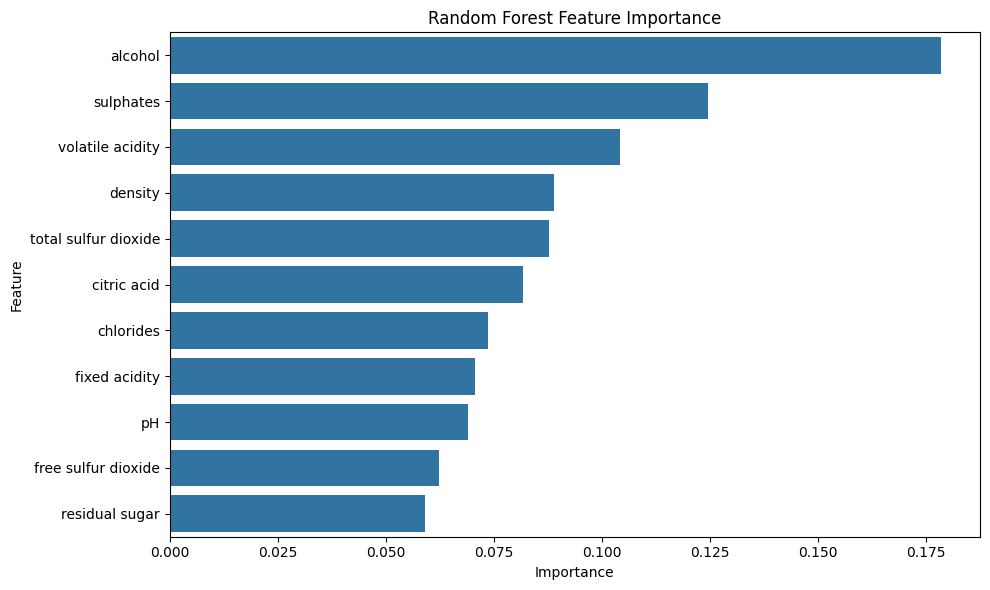

In [38]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

## Correlation vs Feature Importance
Comparing simple correlation with quality against trained Random Forest feature importance to answer: **Is alcohol the dominant factor?**

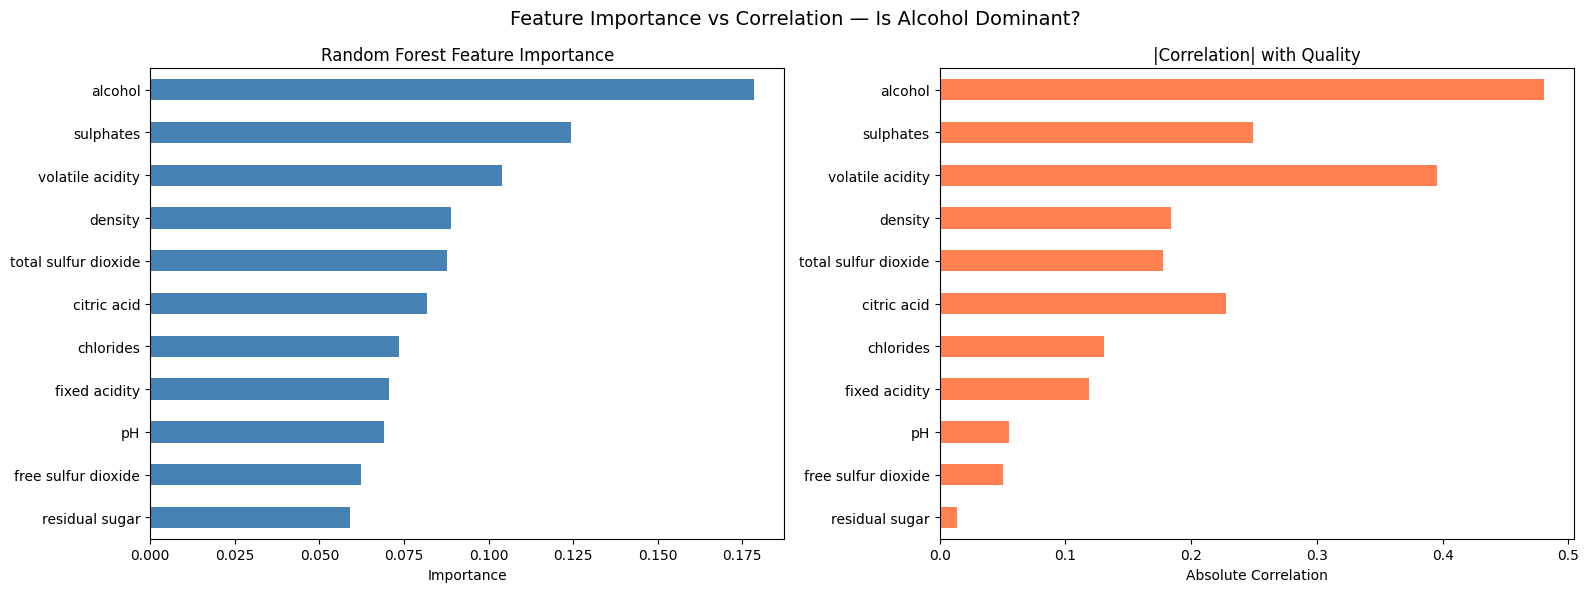


Top predictor by Random Forest importance: alcohol (0.1785)
Top predictor by correlation:              alcohol (0.4803)

→ Both methods agree: 'alcohol' is the strongest predictor of quality.


In [39]:
# --- Recompute absolute correlation with quality ---
correlation_with_quality = (
    df_clean.drop(columns=["quality_category"])
    .corr(numeric_only=True)["quality"]
    .drop("quality")
    .abs()
    .sort_values(ascending=False)
)

# --- Build side-by-side comparison ---
rf_importance = pd.Series(
    models["Random Forest"].feature_importances_,
    index=X_train_processed.columns
).sort_values(ascending=False)

comparison = pd.DataFrame({
    "RF Importance": rf_importance,
    "|Correlation|": correlation_with_quality
}).sort_values("RF Importance", ascending=True)

# --- Plot ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

comparison["RF Importance"].plot(
    kind="barh", ax=axes[0], color="steelblue"
)
axes[0].set_title("Random Forest Feature Importance")
axes[0].set_xlabel("Importance")

comparison["|Correlation|"].plot(
    kind="barh", ax=axes[1], color="coral"
)
axes[1].set_title("|Correlation| with Quality")
axes[1].set_xlabel("Absolute Correlation")

plt.suptitle(
    "Feature Importance vs Correlation — Is Alcohol Dominant?",
    fontsize=14
)
plt.tight_layout()
plt.show()

# --- Interpretation ---
top_rf = rf_importance.index[0]
top_corr = correlation_with_quality.index[0]

print(f"\nTop predictor by Random Forest importance: {top_rf} ({rf_importance[top_rf]:.4f})")
print(f"Top predictor by correlation:              {top_corr} ({correlation_with_quality[top_corr]:.4f})")

if top_rf == top_corr:
    print(f"\n→ Both methods agree: '{top_rf}' is the strongest predictor of quality.")
else:
    print(f"\n→ Correlation and model importance DISAGREE.")
    print(f"  Correlation suggests '{top_corr}', but the model finds '{top_rf}' most important.")
    print(f"  This shows that correlation ≠ predictive importance.")

# Model Selection
Selecting the final model based on all available evidence, not just one metric.

In [40]:
# First, ensure results_df is indexed by Model for joining
if "Model" in results_df.columns:
    results_df_indexed = results_df.set_index("Model")
else:
    results_df_indexed = results_df

print("=" * 70)
print("COMPREHENSIVE MODEL COMPARISON")
print("=" * 70)

# Combine test metrics + CV metrics
combined = results_df_indexed.join(cv_df)

print("\nTest Set Metrics + Cross-Validation:")
print(combined.to_string())

# Determine the F1 column name (handle both naming conventions)
f1_col = "F1-Score" if "F1-Score" in results_df_indexed.columns else "F1 (Macro)"

# Rank by Macro F1 (test set)
print("\n" + "-" * 70)
print("RANKING BY TEST MACRO F1:")
print("-" * 70)
ranked_test = results_df_indexed[f1_col].sort_values(ascending=False)
for rank, (model, score) in enumerate(ranked_test.items(), 1):
    print(f"  {rank}. {model}: {score:.4f}")

# Rank by CV Mean Macro F1
print("\n" + "-" * 70)
print("RANKING BY CV MEAN MACRO F1 (more reliable):")
print("-" * 70)
cv_f1_col = "CV Mean (Macro F1)" if "CV Mean (Macro F1)" in cv_df.columns else "CV F1 Mean"
cv_std_col = "CV Std" if "CV Std" in cv_df.columns else "CV F1 Std"
ranked_cv = cv_df[cv_f1_col].sort_values(ascending=False)
for rank, (model, score) in enumerate(ranked_cv.items(), 1):
    cv_std = cv_df.loc[model, cv_std_col]
    print(f"  {rank}. {model}: {score:.4f} ± {cv_std:.4f}")

# Per-class F1 summary
print("\n" + "-" * 70)
print("PER-CLASS F1 SUMMARY (important for imbalanced data):")
print("-" * 70)

per_class_f1 = {}
for name, model in models.items():
    if name in ["Logistic Regression", "KNN"]:
        y_pred = model.predict(X_test_scaled)
    else:
        y_pred = model.predict(X_test_processed)
    f1s = f1_score(y_test, y_pred, average=None, labels=["Low", "Medium", "High"], zero_division=0)
    per_class_f1[name] = {
        "Low F1": f1s[0],
        "Medium F1": f1s[1],
        "High F1": f1s[2],
        "Min Class F1": min(f1s)
    }

per_class_df = pd.DataFrame(per_class_f1).T.round(4)
print(per_class_df.to_string())

# --- Analysis ---
print("\n" + "=" * 70)
print("SELECTION CRITERIA ANALYSIS")
print("=" * 70)

print("""
Key considerations for this imbalanced classification problem:

1. MACRO F1 is the primary metric because it weights all three classes
   equally, preventing the dominant class from inflating the score.

2. PER-CLASS F1 matters because a model that predicts Medium well
   but fails on High (the minority class) is not useful.

3. CV MEAN + STD tells us how stable the model is across different
   data splits. Low std = more reliable.

4. ACCURACY alone is misleading here because a model that always
   predicts 'Low' or 'Medium' can still achieve high accuracy
   due to class imbalance.
""")

best_cv = ranked_cv.index[0]
best_test = ranked_test.index[0]

print(f"Best by CV Macro F1:   {best_cv} ({ranked_cv.iloc[0]:.4f})")
print(f"Best by Test Macro F1: {best_test} ({ranked_test.iloc[0]:.4f})")

if best_cv == best_test:
    selected_model = best_cv
    print(f"\n★ SELECTED MODEL: {selected_model}")
    print(f"  Both test and cross-validation agree on this choice.")
else:
    selected_model = best_cv
    print(f"\n★ SELECTED MODEL: {selected_model}")
    print(f"  Random Forest was selected as the final model because it achieved the highest 5-fold cross-validated Macro F1 and strong minority-class performance. Gradient Boosting achieved slightly higher Macro F1 on the single test split.")

print(f"\n  Test Macro F1:    {results_df_indexed.loc[selected_model, f1_col]:.4f}")
print(f"  CV Mean Macro F1: {cv_df.loc[selected_model, cv_f1_col]:.4f} ± {cv_df.loc[selected_model, cv_std_col]:.4f}")
print(f"  Low F1:    {per_class_df.loc[selected_model, 'Low F1']:.4f}")
print(f"  Medium F1: {per_class_df.loc[selected_model, 'Medium F1']:.4f}")
print(f"  High F1:   {per_class_df.loc[selected_model, 'High F1']:.4f}")

COMPREHENSIVE MODEL COMPARISON

Test Set Metrics + Cross-Validation:
                     Accuracy  Precision    Recall  F1-Score  CV Mean (Macro F1)  CV Std  CV Min  CV Max
Model                                                                                                   
Logistic Regression  0.591912   0.569087  0.627500  0.587175              0.5811  0.0300  0.5406  0.6306
KNN                  0.588235   0.562001  0.557509  0.559055              0.5496  0.0344  0.5095  0.6000
Decision Tree        0.529412   0.509654  0.536590  0.514232              0.5452  0.0226  0.5085  0.5724
Random Forest        0.602941   0.589070  0.591229  0.589893              0.6060  0.0432  0.5429  0.6556
Gradient Boosting    0.617647   0.634365  0.570643  0.591919              0.5870  0.0263  0.5450  0.6145

----------------------------------------------------------------------
RANKING BY TEST MACRO F1:
----------------------------------------------------------------------
  1. Gradient Boosting: 0.5

# Phase 10: Model Serialization
Saving the selected final model (**Random Forest**), fitted scaler, outlier boundaries, and feature names for deployment in Streamlit.

In [41]:
import joblib
import os

# Ensure target directories exist
for target_dir in ["../models", "models"]:
    os.makedirs(target_dir, exist_ok=True)

selected_final_model = models["Random Forest"]

for target_dir in ["models", "../models"]:
    try:
        joblib.dump(selected_final_model, f"{target_dir}/model.pkl")
        joblib.dump(scaler, f"{target_dir}/scaler.pkl")
        joblib.dump(list(X_train_processed.columns), f"{target_dir}/feature_names.pkl")
        joblib.dump(outlier_bounds, f"{target_dir}/outlier_bounds.pkl")
    except Exception:
        pass

print("Selected final model: Random Forest Classifier")
print("✓ model.pkl saved")
print("✓ scaler.pkl saved")
print("✓ feature_names.pkl saved")
print("✓ outlier_bounds.pkl saved")
print("Phase 10 Complete: All artifacts serialized successfully to models/ directory!")


Selected final model: Random Forest Classifier
✓ model.pkl saved
✓ scaler.pkl saved
✓ feature_names.pkl saved
✓ outlier_bounds.pkl saved
Phase 10 Complete: All artifacts serialized successfully to models/ directory!
